# Method comparison -- in-silico detection and detection limit

Reads only `results/*.csv`, so every pipeline / scenario written by `eval/build_results.sh` shows up
here on the next run. Rows = method x scenario (`zero_shot`: no information from the held-out batch;
`adaptation`: half of the held-out batch's HC used, cross-fitted -- mean-only shift for p0/p2 and the
outlier methods, BLUP for p1). CV has no adaptation scenario (every batch is already in training).

- in-silico sweep = `MethodComparison/sweep.py` design (nb5), all held-out HC of each fold / batch
- detection limit = `3_detection_limit.ipynb` design, half-boot of the held-out HC

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

parent_dir = str(Path.cwd().parent)
if parent_dir not in sys.path:
    sys.path.insert(0, parent_dir)
from viz_style import FS_ANNOT_SM, apply_style
apply_style()

import _FinalModelingMethodImprovement.config as config

Q = 0.05
METRICS = ['Precision', 'Recall', 'F1', 'FDR', 'FP per sample']
FIG_DIR = config.RESULTS_DIR / 'Figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

NAMES = {'p0': 'p0 current', 'p1': 'p1 BLUP', 'p2': 'p2 RUV', **config.OUTLIER_ARMS}
COLORS = {'p0': '#000000', 'p1': '#0072B2', 'p2': '#009E73', 'autoencoder': '#1B9E77',
          'pca': '#7570B3', 'outsingle': '#D95F02', 'peer': '#E7298A'}
STYLES = {'zero_shot': '-', 'adaptation': '--'}
pd.set_option('display.width', 250)
pd.set_option('display.max_columns', 50)

In [2]:
def summarize(df, unit):
    """Pool tp/fp/fn/tn over folds (or batch x boot) per split x method x scenario x q x log2fc.
    FP per sample = pooled FP / pooled number of scored samples."""
    keys = ['split', 'method', 'scenario', 'q', 'log2fc']
    g = df.groupby(keys)[['tp', 'fp', 'fn', 'tn']].sum()
    n = df.groupby(keys + unit)['n_samples'].first().groupby(keys).sum()
    tp, fp, fn = g['tp'], g['fp'], g['fn']
    out = pd.DataFrame({'Precision': tp / (tp + fp), 'Recall': tp / (tp + fn),
                        'F1': 2 * tp / (2 * tp + fp + fn), 'FDR': fp / (tp + fp),
                        'FP per sample': fp / n}).reset_index()
    out['label'] = out['method'].map(NAMES).fillna(out['method']) + ' / ' + out['scenario']
    return out


def tables(s, title):
    for split, sub in s[s['q'] == Q].groupby('split'):
        print(f'===== {title} | {split} | q={Q}')
        for m in METRICS:
            t = sub.pivot_table(index='label', columns='log2fc', values=m).round(3 if m != 'FP per sample' else 1)
            print(f'--- {m}')
            display(t)


def figure(s, title, fname):
    s = s[s['q'] == Q]
    splits = sorted(s['split'].unique())
    fig, axes = plt.subplots(len(METRICS), len(splits), figsize=(4.2 * len(splits), 2.6 * len(METRICS)),
                             sharex=True, squeeze=False)
    for j, split in enumerate(splits):
        for (method, scen), sub in s[s['split'] == split].groupby(['method', 'scenario']):
            sub = sub.sort_values('log2fc')
            for i, m in enumerate(METRICS):
                axes[i, j].plot(sub['log2fc'], sub[m], color=COLORS.get(method, '#888888'),
                                ls=STYLES.get(scen, ':'), marker='o', ms=3, lw=1.2,
                                label=f'{NAMES.get(method, method)} / {scen}')
        axes[0, j].set_title(f'{title}: {split}')
        axes[-1, j].set_xlabel('Injected log2 fold change')
    for i, m in enumerate(METRICS):
        axes[i, 0].set_ylabel(m)
        if m == 'FP per sample':
            for ax in axes[i]:
                ax.set_yscale('symlog', linthresh=10)
        if m == 'FDR':
            for ax in axes[i]:
                ax.axhline(Q, color='red', ls=':', lw=0.8)
    handles, labels = axes[0, -1].get_legend_handles_labels()
    for ax in axes.flat:
        for h, l in zip(*ax.get_legend_handles_labels()):
            if l not in labels:
                handles.append(h)
                labels.append(l)
    fig.legend(handles, labels, loc='center left', bbox_to_anchor=(1.0, 0.5), frameon=False, fontsize=FS_ANNOT_SM)
    fig.tight_layout()
    fig.savefig(FIG_DIR / fname, dpi=300, bbox_inches='tight')
    plt.show()

## In-silico detection (sweep design)

In [3]:
ins = summarize(pd.read_csv(config.INSILICO_CSV), unit=['fold'])
ins.to_csv(config.RESULTS_DIR / 'summary_insilico.csv', index=False)
tables(ins, 'in-silico')

===== in-silico | cv | q=0.05
--- Precision


log2fc,0.0,1.0,2.0,3.0,4.0,5.0
label,,,,,,
OUTRIDER (AE) / zero_shot,0.041,0.164,0.398,0.500,0.540,0.559
OutSingle / zero_shot,0.041,0.126,0.217,0.257,0.269,0.269
PCA / zero_shot,0.042,0.162,0.434,0.560,0.620,0.653
PEER / zero_shot,0.042,0.101,0.285,0.433,0.535,0.590


--- Recall


log2fc,0.0,1.0,2.0,3.0,4.0,5.0
label,,,,,,
OUTRIDER (AE) / zero_shot,0.033,0.152,0.507,0.754,0.871,0.922
OutSingle / zero_shot,0.105,0.356,0.705,0.900,0.977,0.995
PCA / zero_shot,0.022,0.093,0.384,0.645,0.820,0.932
PEER / zero_shot,0.022,0.057,0.218,0.448,0.713,0.916


--- F1


...

log2fc,0.0,1.0,2.0,3.0,4.0,5.0
label,,,,,,
OUTRIDER (AE) / zero_shot,0.046,0.162,0.397,0.533,0.584,0.605
OutSingle / zero_shot,0.065,0.159,0.270,0.319,0.329,0.328
PCA / zero_shot,0.041,0.137,0.362,0.516,0.611,0.658
PEER / zero_shot,0.035,0.079,0.242,0.422,0.580,0.663


--- FDR


log2fc,0.0,1.0,2.0,3.0,4.0,5.0
label,,,,,,
OUTRIDER (AE) / zero_shot,0.959,0.861,0.689,0.601,0.568,0.554
OutSingle / zero_shot,0.959,0.902,0.836,0.808,0.803,0.804
PCA / zero_shot,0.959,0.867,0.688,0.584,0.526,0.496
PEER / zero_shot,0.959,0.911,0.762,0.632,0.536,0.491


--- FP per sample


log2fc,0.0,1.0,2.0,3.0,4.0,5.0
label,,,,,,
OUTRIDER (AE) / zero_shot,617.3,604.4,605.8,600.4,591.9,585.3
OutSingle / zero_shot,1882.2,1894.7,1949.4,1984.0,2010.0,2041.4
PCA / zero_shot,477.1,461.8,476.1,477.6,474.2,469.0
PEER / zero_shot,362.3,366.0,394.2,423.6,446.2,458.8


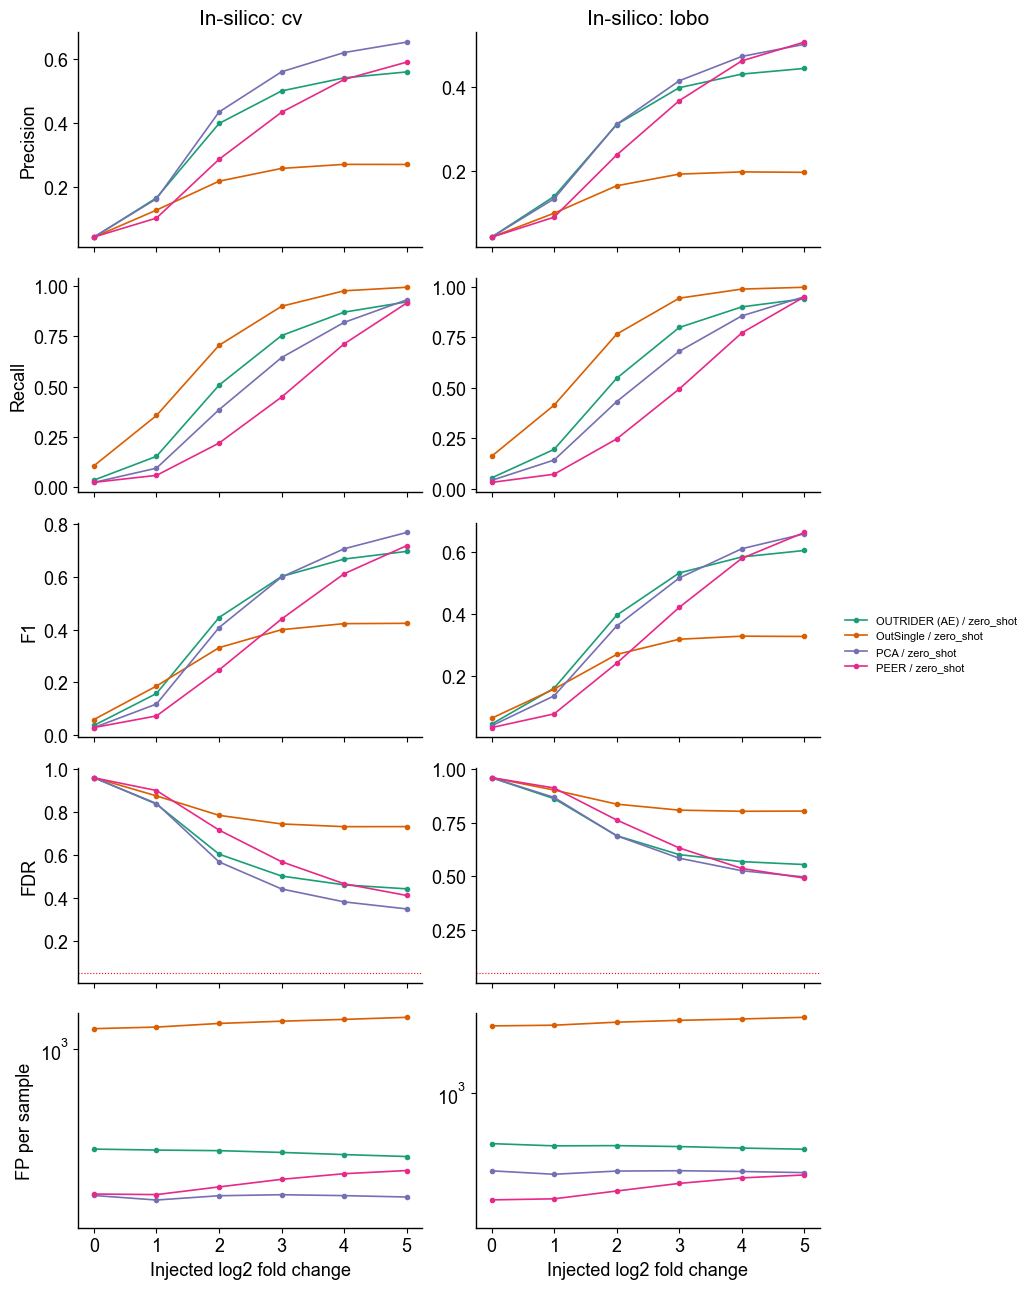

In [4]:
figure(ins, 'In-silico', 'insilico_by_log2fc.png')

### Null calibration (log2fc = 0): false calls per sample at every q

In [7]:
null = ins[ins['log2fc'] == 0].pivot_table(index=['split', 'label'], columns='q', values='FP per sample')
display(null.round(1))

q                                  0.05    0.10    0.20    0.25
split label                                                    
cv    OUTRIDER (AE) / zero_shot   390.0   477.3   619.2   685.6
      OutSingle / zero_shot      1213.9  1501.5  1951.2  2154.8
      PCA / zero_shot             251.8   321.5   434.0   488.2
      PEER / zero_shot            255.3   348.5   511.7   594.9
lobo  OUTRIDER (AE) / zero_shot   617.3   756.9   982.9  1089.0
      OutSingle / zero_shot      1882.2  2345.9  3065.4  3390.5
      PCA / zero_shot             477.1   593.4   779.7   864.9
      PEER / zero_shot            362.3   485.2   712.1   828.2

## Detection limit (nb3 design)

In [8]:
dl = summarize(pd.read_csv(config.DETECTION_LIMIT_CSV), unit=['batch', 'boot'])
dl.to_csv(config.RESULTS_DIR / 'summary_detection_limit.csv', index=False)
tables(dl, 'detection limit')

FileNotFoundError: [Errno 2] No such file or directory: '/project/cfRNA_NormativeModeling_method/_FinalModelingMethodImprovement/results/detection_limit.csv'

In [9]:
figure(dl, 'Detection limit', 'detection_limit_by_log2fc.png')

NameError: name 'dl' is not defined

In [ ]:
null_dl = dl[dl['log2fc'] == 0].pivot_table(index=['split', 'label'], columns='q', values='FP per sample')
display(null_dl.round(1))